# **Customer Churn Prediction using Machine Learning**
This notebook demonstrates the use of machine learning techniques to predict customer churn based on various customer attributes and account information. The insights gained from this analysis can help businesses take proactive measures to retain customers and improve their overall customer relationship management strategies.


# **Importing Libraries**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, confusion_matrix, roc_curve
from sklearn.model_selection import cross_val_score, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# **Dataset Description**
The data set includes information about:


- Customers who left within the last month – the column is called Churn
- Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
- Customer account information – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges
- Demographic info about customers – gender, age range, and if they have partners and dependents

In [ ]:
pip install seaborn

In [ ]:
# Load the dataset
pd.read_csv("dataset/Telco-Customer-Churn.csv")

## **Exploratory Data Analysis**
Performing exploration to understand its structure and contents, and also visualizing the data to uncover patterns and insights

In [38]:
# View the list of columns in the dataset
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [39]:
# View the first 5 rows of the dataset
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [40]:
# View the last 5 rows of the dataset
data.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [41]:
# Check for missing values
print(data.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [42]:
# more information about the dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [43]:
# summary statistic
data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [44]:
# view the shape of the dataset
data.shape

(7043, 21)

In [45]:
# Check for Duplicates
data.duplicated().sum()

0

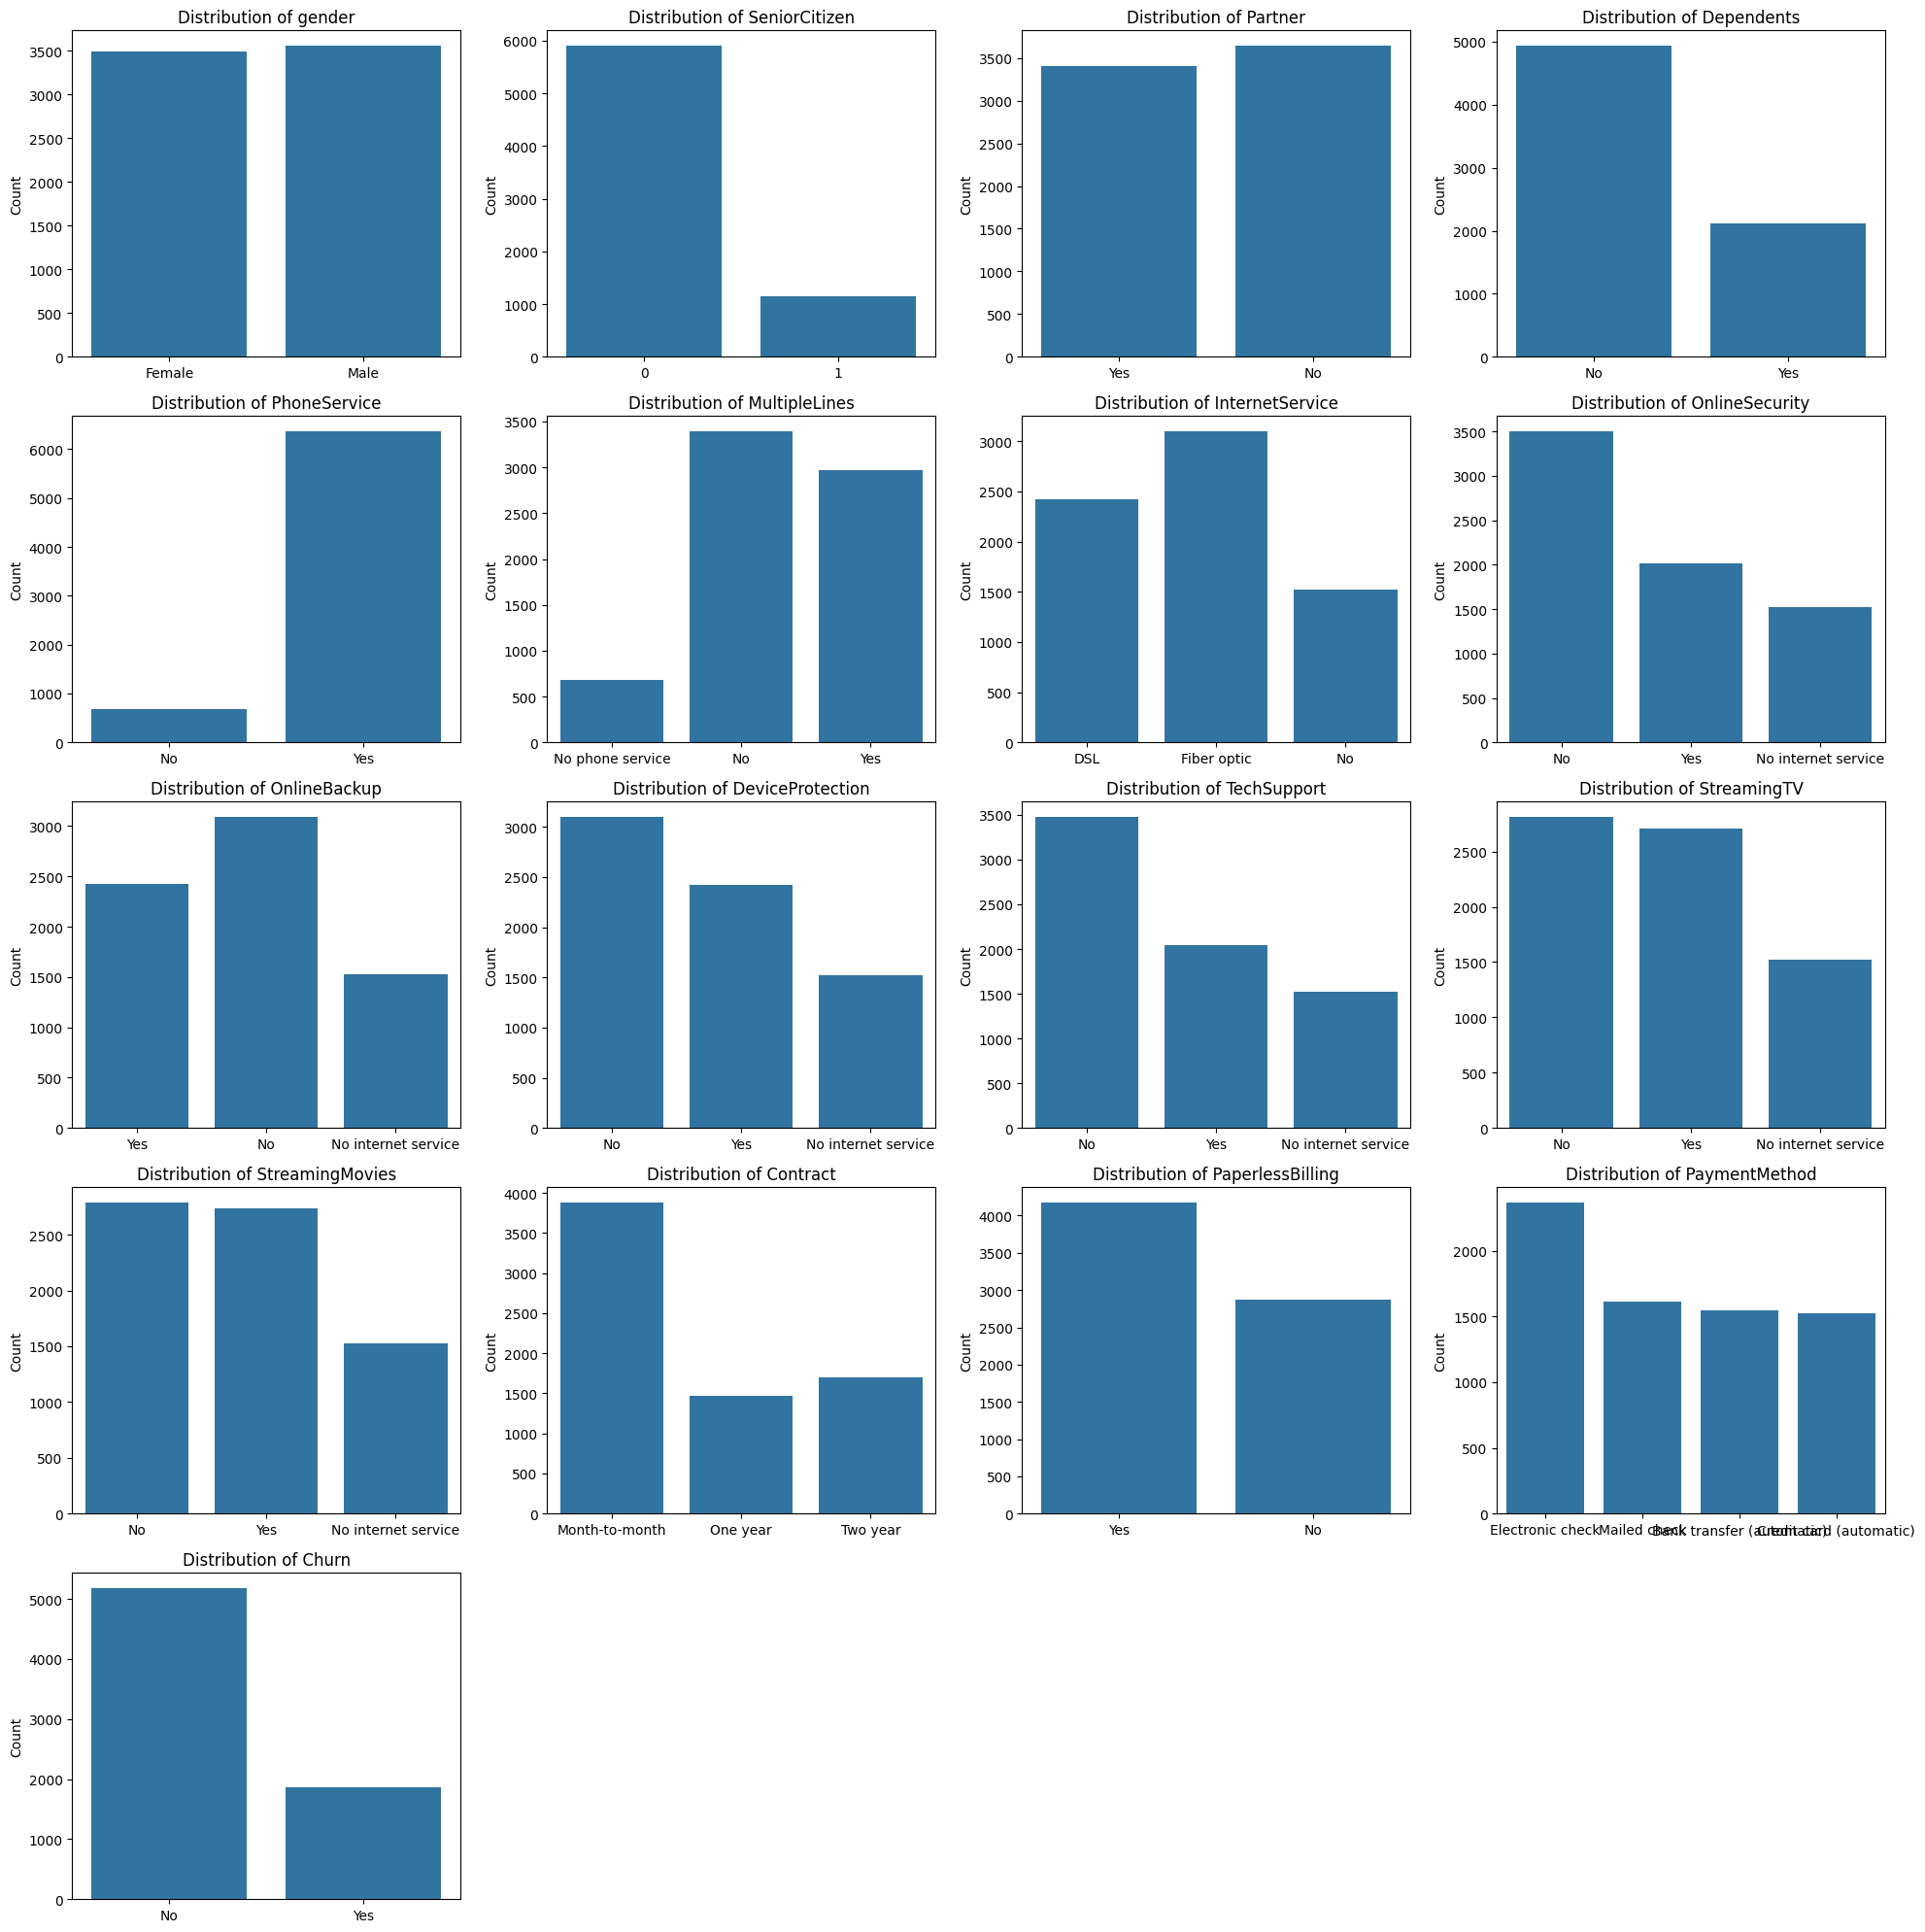

In [46]:
# List of categorical variables
cat_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
                    'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
                    'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

# subplots for each categorical variable
plt.figure(figsize=(20, 20))
for i, col in enumerate(cat_features, 1):
    plt.subplot(5, 4, i)
    sns.countplot(data=data, x=col)
    plt.title(f'Distribution of {col}')
    plt.xlabel('')
    plt.ylabel('Count')

# Adjust layout
plt.tight_layout()
plt.show()


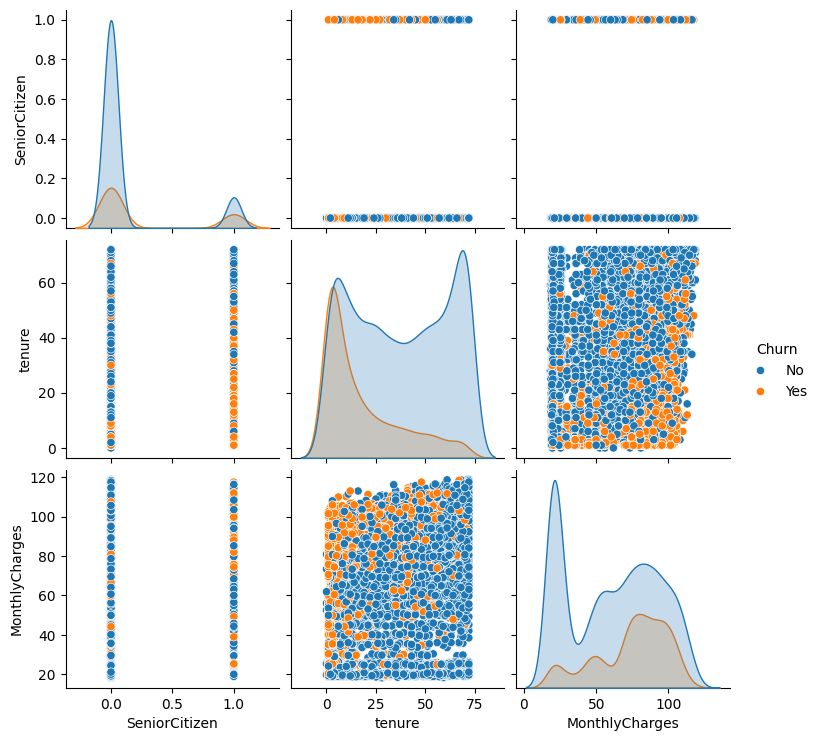

In [47]:
# Create pair plots
sns.pairplot(data, hue='Churn')
plt.show()

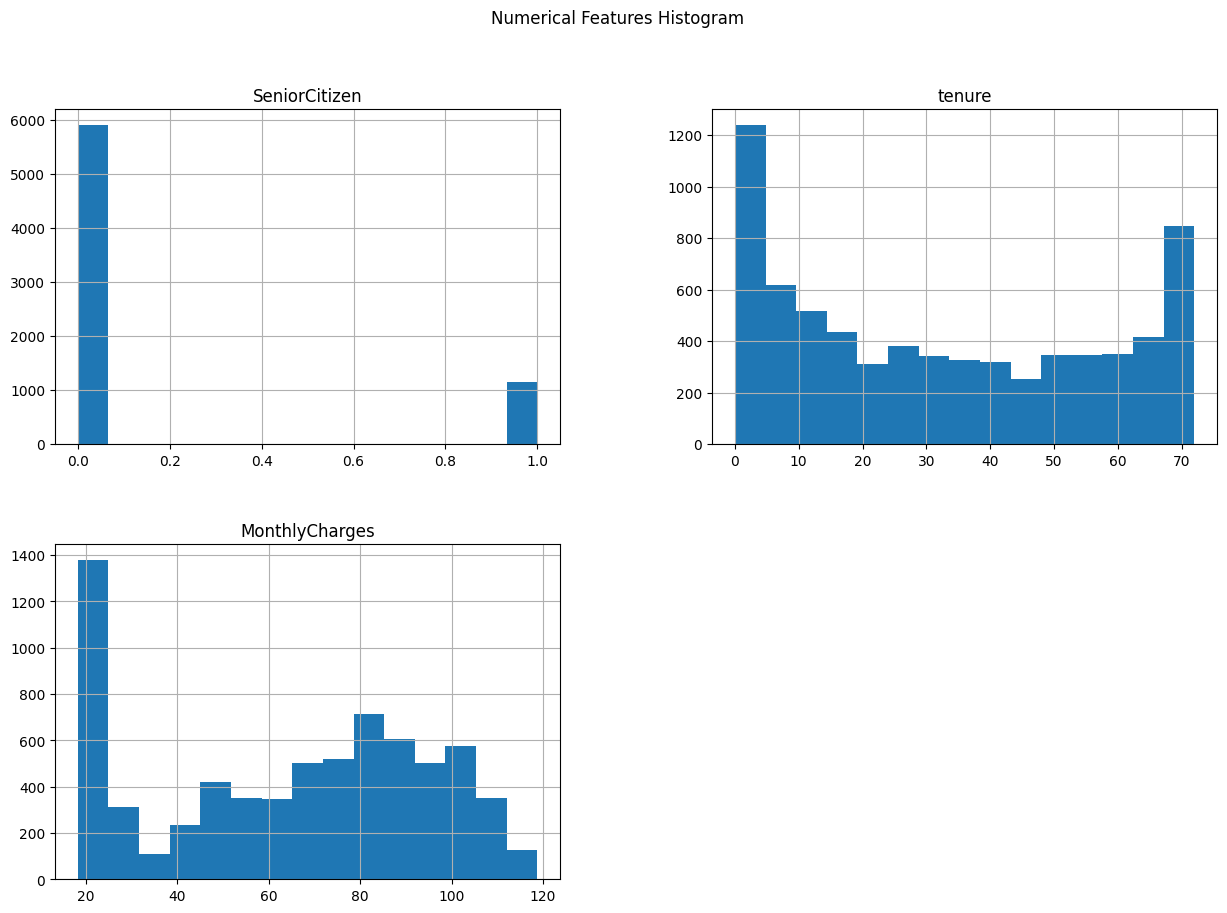

In [48]:
# Visualizing the distribution of the numerical features using histogram
num_features = data.select_dtypes(include=['int64', 'float64']).columns
data[num_features].hist(bins=15,figsize=(15,10))
plt.suptitle('Numerical Features Histogram')
plt.show()


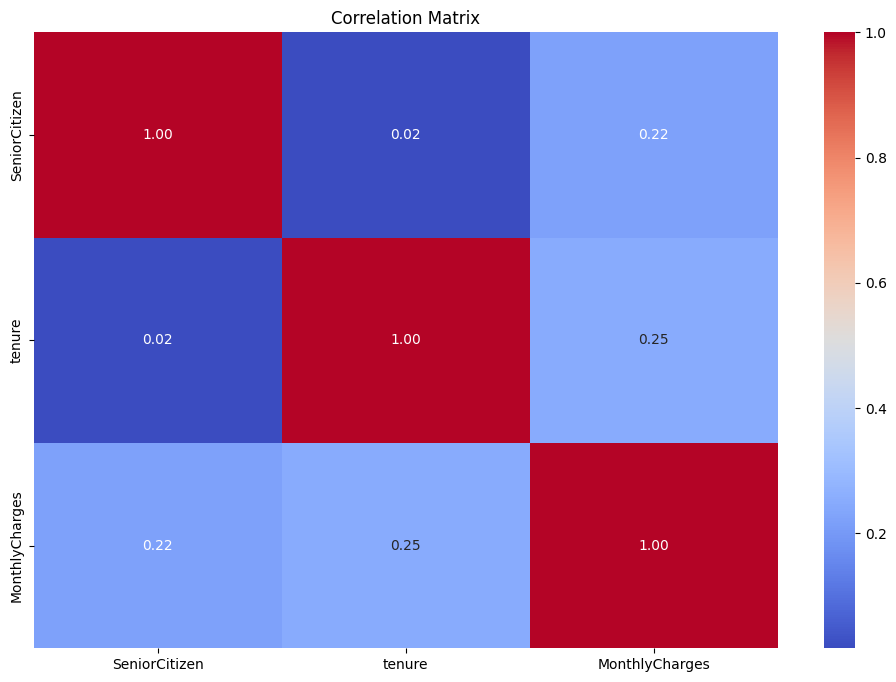

In [49]:
# correction matrix
correction_matrix = data[num_features].corr()
plt.figure(figsize=(12,8))
sns.heatmap(correction_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

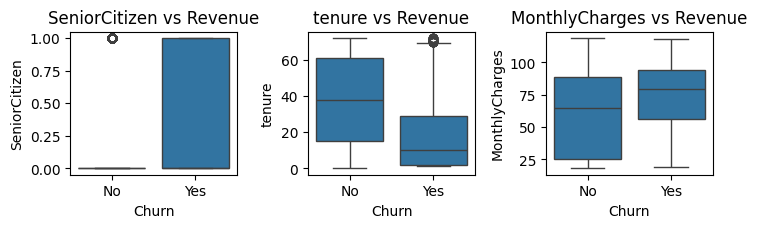

In [50]:
# Relationship with target variable
plt.figure(figsize=(12, 8))
for i, col in enumerate(num_features):
    plt.subplot(4, 5, i+1)
    sns.boxplot(x=data['Churn'], y=data[col])
    plt.title(f'{col} vs Revenue')
plt.tight_layout()
plt.show()

# **Data Preprocessing**
This is to preprocess the data to prepare it for model training

In [51]:
# Encode categorical features with Label encoder
encoder = {}
for feature in cat_features:
  encoder[feature] = LabelEncoder()
  data[feature] = encoder[feature].fit_transform(data[feature])

In [52]:
# Convert the TotalCharges column to numeric, coercing errors to NaN
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')

In [53]:
# Check for any remaining non-numeric entries
print(data['TotalCharges'].isnull().sum())

11


In [54]:
# Impute missing values with the mean
data['TotalCharges'] = data['TotalCharges'].fillna(data['TotalCharges'].mean())

In [55]:
# Display the new Dtypes
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   int64  
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   int64  
 4   Dependents        7043 non-null   int64  
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   int64  
 7   MultipleLines     7043 non-null   int64  
 8   InternetService   7043 non-null   int64  
 9   OnlineSecurity    7043 non-null   int64  
 10  OnlineBackup      7043 non-null   int64  
 11  DeviceProtection  7043 non-null   int64  
 12  TechSupport       7043 non-null   int64  
 13  StreamingTV       7043 non-null   int64  
 14  StreamingMovies   7043 non-null   int64  
 15  Contract          7043 non-null   int64  
 16  PaperlessBilling  7043 non-null   int64  


# **Separate the features and target variable.**

In [56]:
# Defining the feature and target variables
X = data.drop(['Churn', 'customerID'], axis=1)
y = data['Churn']

In [57]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42)


#**Handling Imbalances**
To address the class imbalance in the target variable, Synthetic Minority Over-sampling Technique (SMOTE) was used to resample the training data.

In [58]:
# Resample the training data
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# **Model Training**
Training three machine learning models on the resampled training data

In [70]:
# Train and fit the XGBoost model on the resampled training data
xgb_model = xgb.XGBClassifier(random_state=42)
xgb_model.fit(X_train_resampled, y_train_resampled)

# Train and it the Random Forest model on the resampled training data
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_resampled, y_train_resampled)

# Train and fit the Gradient Boosting model on the resampled training data
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train_resampled, y_train_resampled)


GradientBoostingClassifier(random_state=42)

# **Model Evaluation**
Evaluating the performance of each model using various metrics, such as accuracy, precision, recall, F1-score, and ROC AUC.

In [71]:
# Make predictions on each model
y_pred_xgb = xgb_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)
y_pred_gb = gb_model.predict(X_test)

In [72]:
# Predict the probabilities for the positive class (class 1) for each model
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]
y_pred_proba_gb = gb_model.predict_proba(X_test)[:, 1]

In [73]:
# Evaluate performance for XGBoost
print("XGBoost Evaluation")
print(f'Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}')
print(f'Precision: {precision_score(y_test, y_pred_xgb):.4f}')
print(f'Recall: {recall_score(y_test, y_pred_xgb):.4f}')
print(f'F1-score: {f1_score(y_test, y_pred_xgb):.4f}')
print(f'ROC AUC: {roc_auc_score(y_test, y_pred_proba_xgb):.4f}\n')

# Evaluate performance for Random Forest
print("Random Forest Evaluation")
print(f'Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}')
print(f'Precision: {precision_score(y_test, y_pred_rf):.4f}')
print(f'Recall: {recall_score(y_test, y_pred_rf):.4f}')
print(f'F1-score: {f1_score(y_test, y_pred_rf):.4f}')
print(f'ROC AUC: {roc_auc_score(y_test, y_pred_proba_rf):.4f}\n')

# Evaluate performance for Gradient Boosting
print("Gradient Boost Evaluation")
print(f'Accuracy: {accuracy_score(y_test, y_pred_gb):.4f}')
print(f'Precision: {precision_score(y_test, y_pred_gb):.4f}')
print(f'Recall: {recall_score(y_test, y_pred_gb):.4f}')
print(f'F1-score: {f1_score(y_test, y_pred_gb):.4f}')
print(f'ROC AUC: {roc_auc_score(y_test, y_pred_proba_gb):.4f}\n')

XGBoost Evaluation
Accuracy: 0.7807
Precision: 0.5847
Recall: 0.5925
F1-score: 0.5885
ROC AUC: 0.8306

Random Forest Evaluation
Accuracy: 0.7743
Precision: 0.5729
Recall: 0.5791
F1-score: 0.5760
ROC AUC: 0.8235

Gradient Boost Evaluation
Accuracy: 0.7821
Precision: 0.5693
Recall: 0.7265
F1-score: 0.6384
ROC AUC: 0.8439



# **Confusion Matrix**
Visualizing the Confusion matrices for each model.

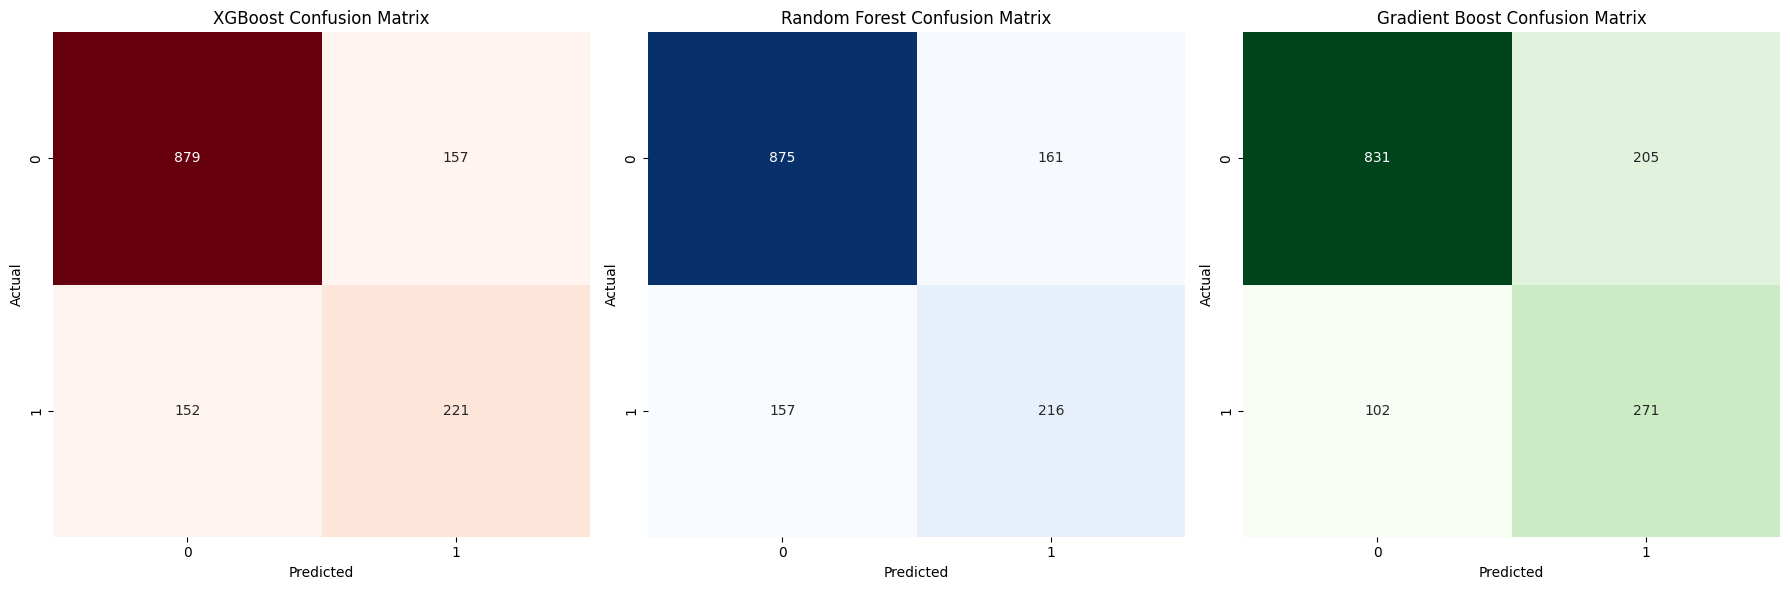

In [74]:
# Plot Confusion Matrix
plt.figure(figsize=(18, 6))

# Confusion Matrix for XGBoost
conf_mat_xgb = confusion_matrix(y_test, y_pred_xgb)
plt.subplot(1, 3, 1)
sns.heatmap(conf_mat_xgb, annot=True, cmap='Reds', fmt='d', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost Confusion Matrix')

# Confusion Matrix for Random Forest
conf_mat_rf = confusion_matrix(y_test, y_pred_rf)
plt.subplot(1, 3, 2)
sns.heatmap(conf_mat_rf, annot=True, cmap='Blues', fmt='d', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')


# Confusion Matrix for Gradient Boost
conf_mat_xgb = confusion_matrix(y_test, y_pred_gb)
plt.subplot(1, 3, 3)
sns.heatmap(conf_mat_xgb, annot=True, cmap='Greens', fmt='d', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Gradient Boost Confusion Matrix')

# Display the plots
plt.tight_layout()
plt.show()

# **Receiver Operating Characteristic (ROC) Curve**
Visualizing the ROC curves for each model.

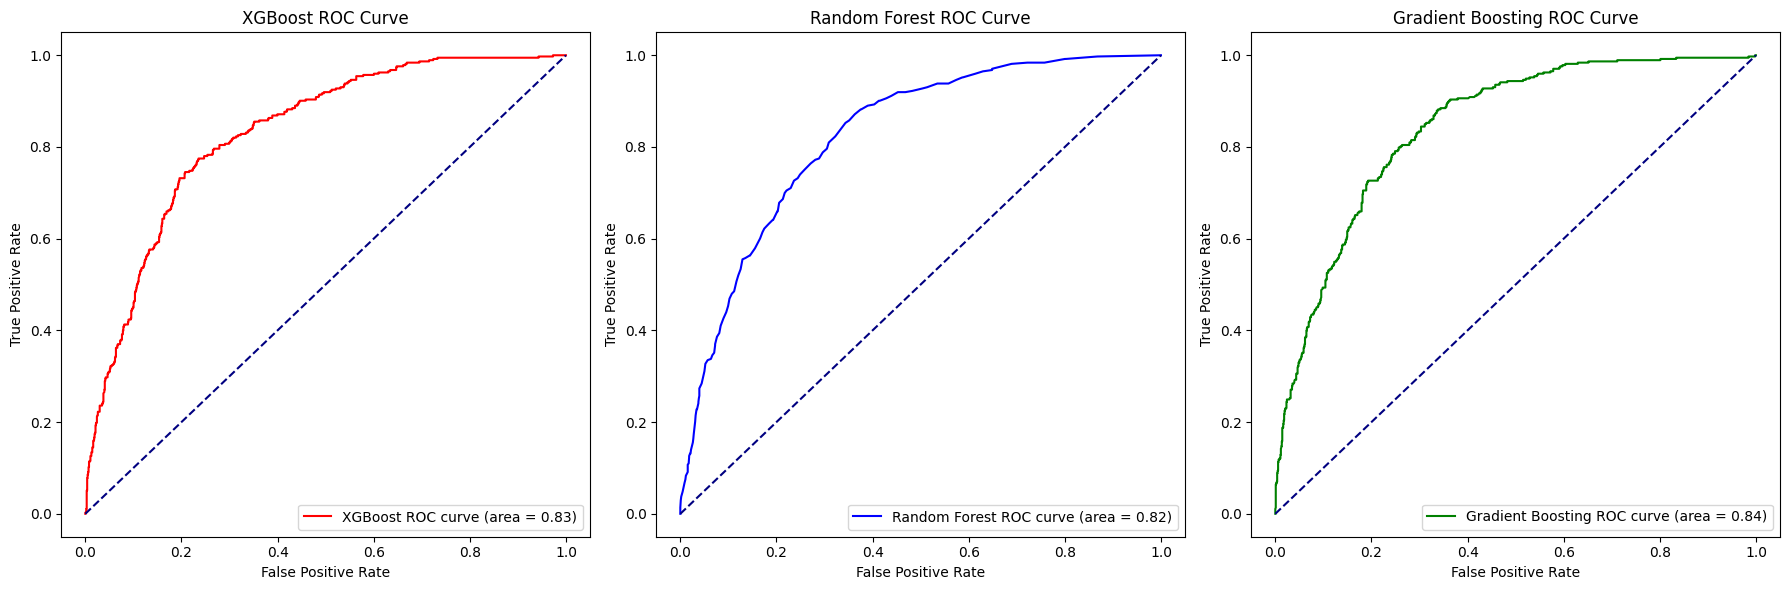

In [75]:
# Plot
plt.figure(figsize=(18, 6))

# ROC Curve for XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_proba_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)
plt.subplot(1, 3, 1)
plt.plot(fpr_xgb, tpr_xgb, color='red', label='XGBoost ROC curve (area = %0.2f)' % roc_auc_xgb)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost ROC Curve')
plt.legend(loc="lower right")

# ROC Curve for Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)
plt.subplot(1, 3, 2)
plt.plot(fpr_rf, tpr_rf, color='blue', label='Random Forest ROC curve (area = %0.2f)' % roc_auc_rf)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC Curve')
plt.legend(loc="lower right")

# ROC Curve for Gradient Boost
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_pred_proba_gb)
roc_auc_gb = roc_auc_score(y_test, y_pred_proba_gb)
plt.subplot(1, 3, 3)
plt.plot(fpr_gb, tpr_gb, color='green', label='Gradient Boosting ROC curve (area = %0.2f)' % roc_auc_gb)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Gradient Boosting ROC Curve')
plt.legend(loc="lower right")

# Display the plots
plt.tight_layout()
plt.show()

# **Cross Validation**

Cross validation is a technique used in machine learning to evaluate the performance of a model on unseen data. It helps ensure that the model is not overfitting and can generalize well to unseen data.




In [65]:
# Using cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# models to use for the cross-validation strategy
models = {
    'XGB': xgb.XGBClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

In [66]:
# Function to evaluate a model using cross-validation
def evaluate_model_cv(model, X, y, cv):
    # Create a pipeline with SMOTE and the model
    pipeline = Pipeline(steps=[('smote', SMOTE(random_state=42)), ('model', model)])
    # Define the evaluation metrics
    metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
    # Perform cross-validation for each metric
    results = {metric: cross_val_score(
        pipeline, X, y, cv=cv, scoring=metric) for metric in metrics}
    return results # Return the cross-validation results

# Evaluate each model
results = {}
for model_name, model in models.items():
    # Store the evaluation results for each model
    results[model_name] = evaluate_model_cv(model, X, y, cv)

# Display results
for model_name, metrics in results.items():
    print(f'\n{model_name} Cross-Validation Results:')  # Print the model name
    for metric, scores in metrics.items():
        # Print the mean and standard deviation of each metric
        print(f'{metric.capitalize()}: {np.mean(scores):.4f} ± {np.std(scores):.4f}')


XGB Cross-Validation Results:
Accuracy: 0.7723 ± 0.0094
Precision: 0.5700 ± 0.0186
Recall: 0.5800 ± 0.0192
F1: 0.5748 ± 0.0155
Roc_auc: 0.8173 ± 0.0071

Random Forest Cross-Validation Results:
Accuracy: 0.7806 ± 0.0084
Precision: 0.5875 ± 0.0160
Recall: 0.5821 ± 0.0234
F1: 0.5847 ± 0.0178
Roc_auc: 0.8204 ± 0.0125

Gradient Boosting Cross-Validation Results:
Accuracy: 0.7723 ± 0.0061
Precision: 0.5577 ± 0.0084
Recall: 0.6838 ± 0.0325
F1: 0.6141 ± 0.0168
Roc_auc: 0.8346 ± 0.0092


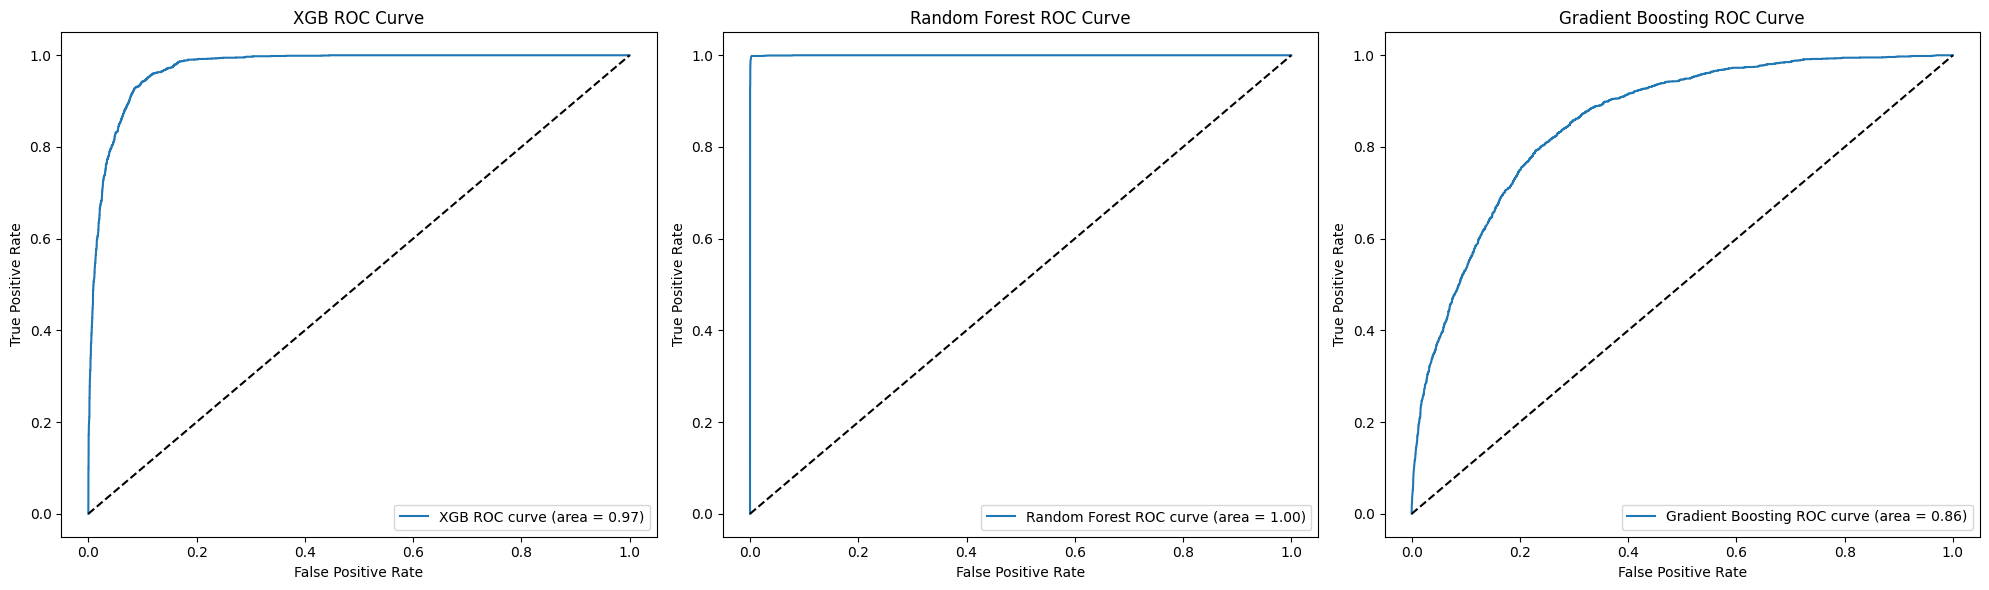

In [67]:
# Train final models and plot ROC curves
# Create a figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Iterate over each model and its corresponding subplot axis
for ax, (name, model) in zip(axes, models.items()):
    # Create a pipeline with SMOTE and the model
    pipeline = Pipeline(steps=[('smote', SMOTE(random_state=42)), ('model',
                                                                   model)])
    pipeline.fit(X, y)  # Fit the pipeline on the entire dataset

    # Predict probabilities for the positive class
    y_pred_proba = pipeline.predict_proba(X)[:, 1]
    # Compute false positive rates and true positive rates for ROC curve
    fpr, tpr, _ = roc_curve(y, y_pred_proba)
    # Compute ROC AUC score
    roc_auc = roc_auc_score(y, y_pred_proba)

    # Plot ROC curve
    ax.plot(fpr, tpr, label=f'{name} ROC curve (area = {roc_auc:.2f})')
    ax.plot([0, 1], [0, 1], 'k--')  # Plot diagonal line
    ax.set_title(f'{name} ROC Curve')  # Set subplot title
    ax.set_xlabel('False Positive Rate')  # Set x-axis label
    ax.set_ylabel('True Positive Rate')  # Set y-axis label
    ax.legend(loc='lower right')  # Place legend in the lower right corner

# Display the plot
plt.tight_layout()
plt.show()


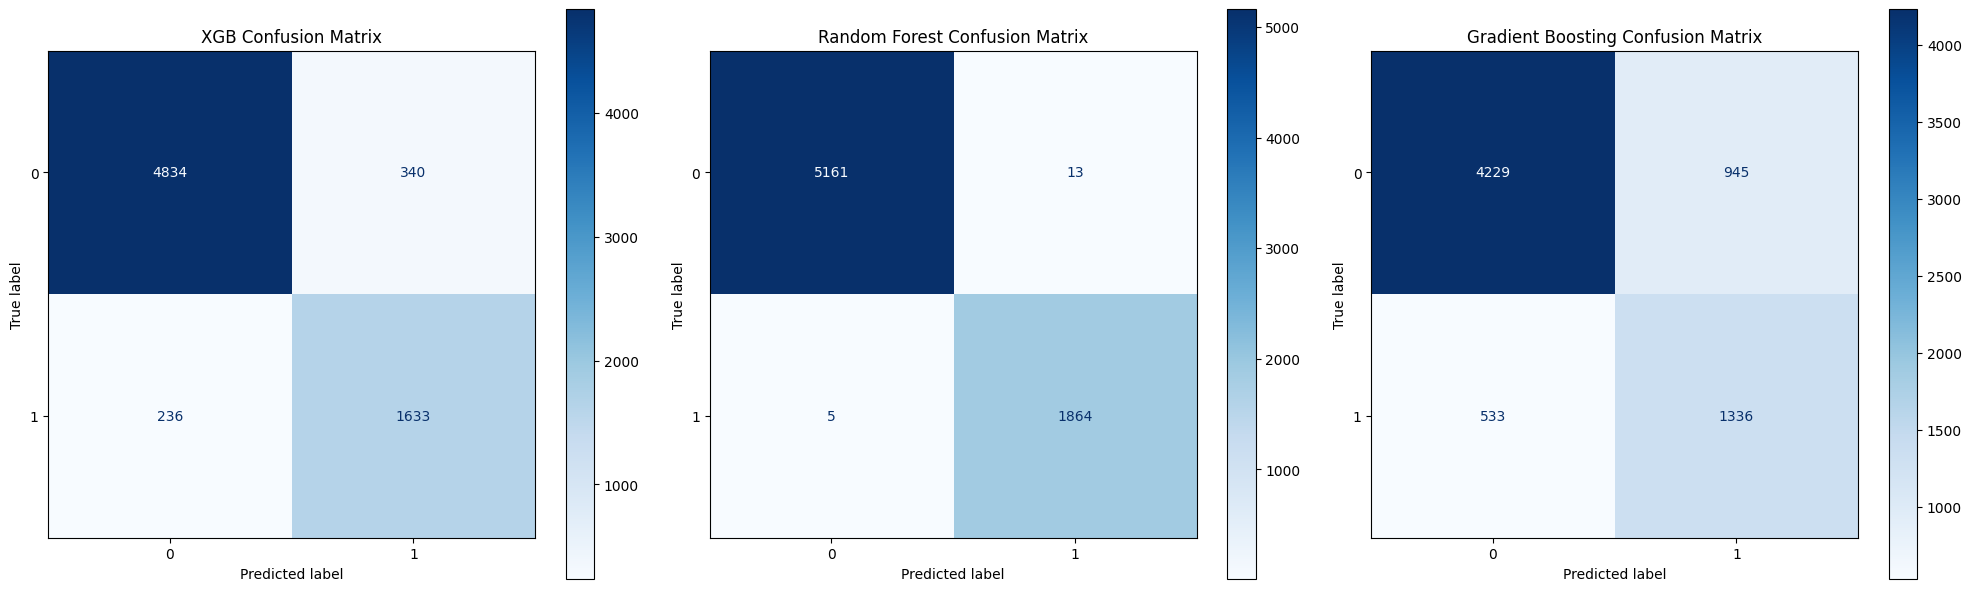

In [68]:
# Plot confusion matrix for each model
# Create a figure with 3 subplots for confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Iterate over each model and its corresponding subplot axis
for ax, (name, model) in zip(axes, models.items()):
    # Create a pipeline with SMOTE and the model
    pipeline = Pipeline(steps=[('smote', SMOTE(random_state=42)), ('model', model)])
    pipeline.fit(X, y)  # Fit the pipeline on the entire dataset
    y_pred = pipeline.predict(X)  # Predict labels for the dataset

    # Compute the confusion matrix
    cm = confusion_matrix(y, y_pred)
    # Create a ConfusionMatrixDisplay object
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    # Plot the confusion matrix with a blue color map
    disp.plot(ax=ax, cmap=plt.cm.Blues)
    ax.set_title(f'{name} Confusion Matrix')  # Set the title for the subplot

plt.tight_layout()  # Adjust subplots to fit in the figure area
plt.show()  # Display the plot

Gradient Boosting is the best overall model in this case, with the highest accuracy and F1-score, and a strong ROC AUC. It performs consistently well both on the test set and across cross-validation folds.
Random Forest shows strong precision, which can be useful if the cost of false positives is high.
XGBoost has balanced performance, slightly behind Gradient Boosting in most metrics.